In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una obra de urbanización empieza el **1 de junio** (semana 1 del proyecto). El cuadro de prelaciones, las duraciones medias (semanas), las desviaciones típicas y si la actividad se ejecuta **al aire libre** (`exterior` = 1) se adjuntan. El plazo contractual es de **23 semanas**.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation, exterior
    ('A'     , '---'      , 3       , 0.6               , 0       ),
    ('B'     , '---'      , 6       , 0.2               , 1       ),
    ('C'     , 'A,B'      , 1       , 0.1               , 1       ),
    ('D'     , 'C'        , 6       , 0.6               , 1       ),
    ('E'     , 'C'        , 5       , 0.3               , 1       ),
    ('F'     , 'D'        , 2       , 0.8               , 1       ),
    ('G'     , 'E,F'      , 3       , 0.2               , 1       ),
    ('H'     , 'G'        , 1       , 0.6               , 0       ),
    ('I'     , 'F'        , 6       , 1                 , 0       ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation', 'exterior']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation,exterior
activity,,,,
A,---,3,0.6,0
B,---,6,0.2,1
C,"A,B",1,0.1,1
D,C,6,0.6,1
E,C,5,0.3,1
F,D,2,0.8,1
G,"E,F",3,0.2,1
H,G,1,0.6,0
I,F,6,1.0,0


Según los registros de la AEMET de los últimos años, en la zona cada semana de julio, agosto y la primera quincena de septiembre (semanas 5 a 14 del proyecto) tiene una probabilidad **50%** de incluir un episodio de aviso naranja o rojo por calor, durante el cual el trabajo al aire libre se interrumpe en las horas centrales: cada episodio supone perder el equivalente a **0.4 semanas** de trabajo en las actividades exteriores en curso.

> **De: Jefe de proyecto**
> El cronograma va con las duraciones medias y así se presenta al cliente. El calor no es un riesgo del proyecto, es el clima: si hay aviso, se trabaja igual y se recupera con horas por la tarde, como siempre. No quiero una reserva de «calor» en el plan, que luego se usa para todo.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S10 — Condiciones de trabajo en la cadena de ejecución.** El plan no puede apoyarse en condiciones de trabajo que la norma prohíbe: ni en una cadena de subcontratación más larga que la permitida, ni en jornadas al aire libre que ignoren los avisos por calor extremo. Una ventaja de coste o plazo obtenida así no es una opción de la tabla (cf. C7 y C5 de la lección 19). *(cf. Ley 32/2006 de subcontratación en la construcción, arts. 4 y 5; RD 486/1997, disposición adicional única (RDL 4/2023); ICB4, Perspectiva 3 «salud, seguridad y medio ambiente».)*
- **S11 — Riesgo de sostenibilidad.** Una amenaza ambiental, climática, regulatoria o social que puede cambiar el plazo, el coste o el resultado del proyecto es un riesgo del proyecto: entra en el registro con su probabilidad y su impacto y se cuantifica en el cronograma como cualquier otro. Dejarlo fuera «porque es el clima» o «porque es de la administración» es retener información (C4 de la lección 19). *(cf. PMBOK 8 §3.7.1 (riesgos de sostenibilidad) y §3.7.3 (dominio de desempeño del riesgo).)*
- **Norma o dato de referencia — en el trabajo al aire libre el empresario adopta las medidas que resulten de la evaluación de riesgos frente a los fenómenos meteorológicos adversos, incluidas las temperaturas extremas; cuando la AEMET emite un aviso de nivel naranja o rojo y las medidas preventivas no garantizan la protección, es obligatorio adaptar las condiciones de trabajo, incluida la reducción o modificación de las horas de la jornada, hasta prohibir determinadas tareas en las horas en que concurre el fenómeno** *(RD 486/1997, disposición adicional única (añadida por el RDL 4/2023, de 11 de mayo).)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Con el calendario de inicios más tempranos, obtenga para cada actividad exterior las semanas que caen en la ventana de calor y la pérdida esperada de duración (semanas × probabilidad × pérdida por episodio). ¿Cuál es la duración esperada del proyecto con la pérdida y qué actividades concentran el riesgo?  "
pregunta_2 = "2. (A) Calcule la probabilidad de cumplir el plazo de 23 semanas sin el calor (aproximación normal del PERT) y con él (simulación Monte Carlo, 20 000 réplicas: duración normal más la pérdida binomial de cada actividad exterior). ¿Qué actividades exteriores podrían salir de la ventana usando su holgura total?  "
pregunta_3 = "3. (B) Según la norma y los criterios de referencia, ¿puede presentarse al cliente el cronograma con las duraciones medias y «se trabaja igual»? ¿Es el calor un riesgo del proyecto?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de proyecto y qué comunica al cliente? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Con el calendario de inicios más tempranos, obtenga para cada actividad exterior las semanas que caen en la ventana de calor y la pérdida esperada de duración (semanas × probabilidad × pérdida por episodio). ¿Cuál es la duración esperada del proyecto con la pérdida y qué actividades concentran el riesgo?  

2. (A) Calcule la probabilidad de cumplir el plazo de 23 semanas sin el calor (aproximación normal del PERT) y con él (simulación Monte Carlo, 20 000 réplicas: duración normal más la pérdida binomial de cada actividad exterior). ¿Qué actividades exteriores podrían salir de la ventana usando su holgura total?  

3. (B) Según la norma y los criterios de referencia, ¿puede presentarse al cliente el cronograma con las duraciones medias y «se trabaja igual»? ¿Es el calor un riesgo del proyecto?  

4. (C) ¿Qué propone al jefe de proyecto y qué comunica al cliente? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
plazo, p_episodio, perdida_episodio, ventana = 23, 0.5, 0.4, (5, 14)
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
def semanas_en_ventana(a):
    es, ef = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
    return max(0, min(ef, ventana[1]) - max(es, ventana[0] - 1)) * int(datos_proyecto.loc[a, 'exterior'])

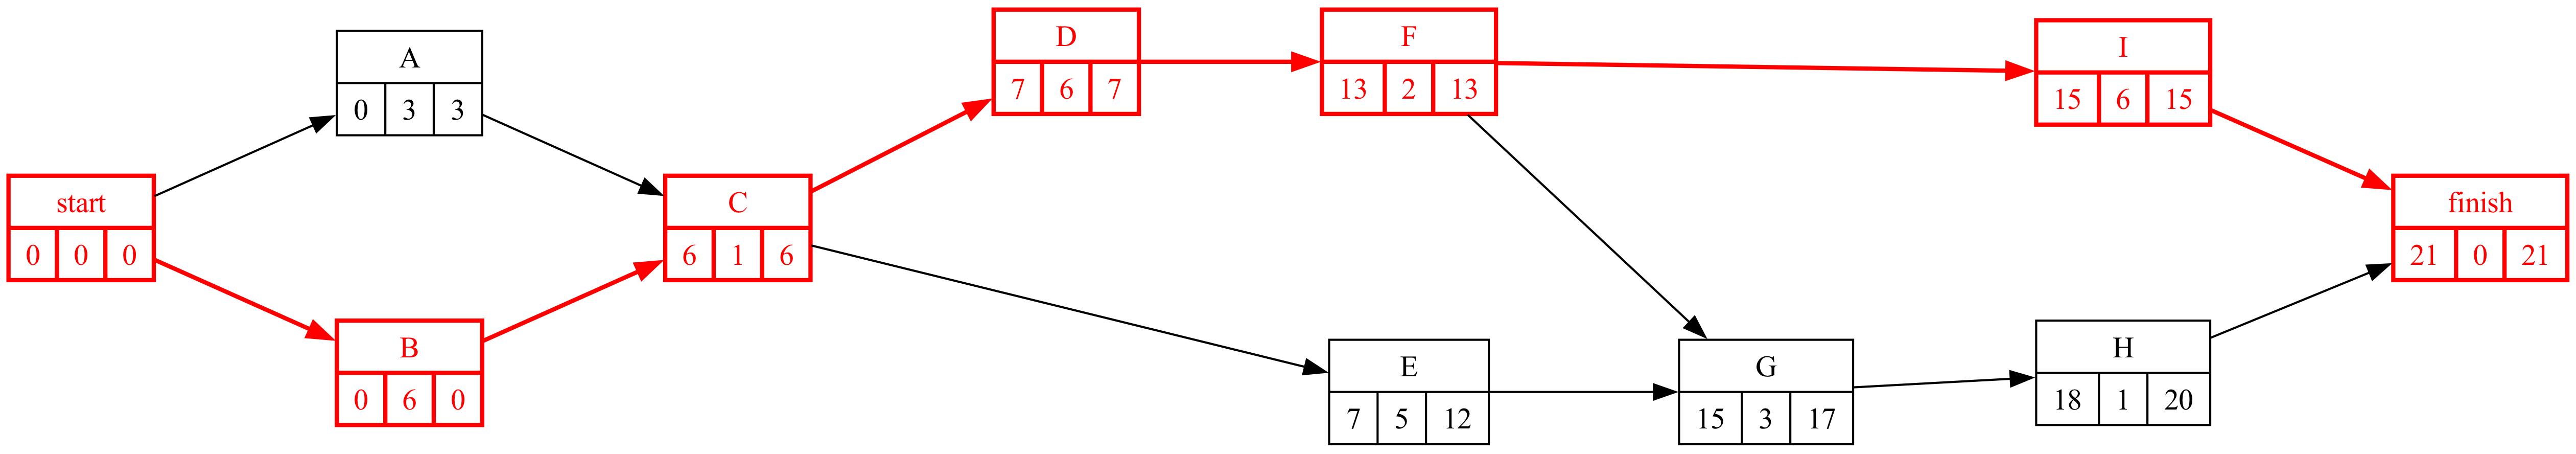

In [8]:
#| fig-cap: "Grafo Roy con las duraciones medias"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = \max\{0+3,\ 0+6\} = 6$ &nbsp; (A, B)
- $T_{D} = 6+1 = 7$ &nbsp; (C)
- $T_{E} = 6+1 = 7$ &nbsp; (C)
- $T_{F} = 7+6 = 13$ &nbsp; (D)
- $T_{G} = \max\{7+5,\ 13+2\} = 15$ &nbsp; (E, F)
- $T_{I} = 13+2 = 15$ &nbsp; (F)
- $T_{H} = 15+3 = 18$ &nbsp; (G)
- $T_{\mathrm{Fin}} = \max\{15+6,\ 18+1\} = 21$ &nbsp; (I, H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 21$
- $T_{H}^{*} = 21-1 = 20$ &nbsp; (Fin)
- $T_{I}^{*} = 21-6 = 15$ &nbsp; (Fin)
- $T_{G}^{*} = 20-3 = 17$ &nbsp; (H)
- $T_{F}^{*} = \min\{17-2,\ 15-2\} = 13$ &nbsp; (G, I)
- $T_{E}^{*} = 17-5 = 12$ &nbsp; (G)
- $T_{D}^{*} = 13-6 = 7$ &nbsp; (F)
- $T_{C}^{*} = \min\{7-1,\ 12-1\} = 6$ &nbsp; (D, E)
- $T_{B}^{*} = 6-6 = 0$ &nbsp; (C)
- $T_{A}^{*} = 6-3 = 3$ &nbsp; (C)
- $T_{\mathrm{Inicio}}^{*} = \min\{3-0,\ 0-0\} = 0$ &nbsp; (A, B)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Con el calendario de inicios más tempranos, obtenga para cada actividad exterior las semanas que caen en la ventana de calor y la pérdida esperada de duración (semanas × probabilidad × pérdida por episodio). ¿Cuál es la duración esperada del proyecto con la pérdida y qué actividades concentran el riesgo?  

In [10]:
#| tbl-cap: "Semanas de cada actividad en la ventana de calor y pérdida esperada"
#| label: tbl-calor
tabla = calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'H_total']].copy()
tabla['exterior'] = datos_proyecto['exterior']
tabla['semanas en la ventana'] = [semanas_en_ventana(a) for a in tabla.index]
tabla['pérdida esperada'] = tabla['semanas en la ventana'] * p_episodio * perdida_episodio
display(tabla.round(2))
duraciones_calor = datos_proyecto['duration'] + tabla['pérdida esperada']
R = proyecto.path_matrix(dummies=False)
duracion_esperada_calor = float((R @ duraciones_calor[R.columns]).max())
criticas_exterior = [a for a in tabla.index if tabla.loc[a, 'H_total'] == 0 and tabla.loc[a, 'semanas en la ventana'] > 0]
Markdown(f'''Duración esperada **{duracion_esperada_calor:.1f}** semanas con la pérdida por calor, frente a {duracion} del plan (+{duracion_esperada_calor - duracion:.1f}). El riesgo se concentra en las actividades exteriores críticas: {', '.join(criticas_exterior)}.''')

,inicio_mas_temprano,fin_mas_temprano,H_total,exterior,semanas en la ventana,pérdida esperada
activity,,,,,,
A,0,3,3,0,0,0.0
B,0,6,0,1,2,0.4
C,6,7,0,1,1,0.2
D,7,13,0,1,6,1.2
E,7,12,5,1,5,1.0
F,13,15,0,1,1,0.2
G,15,18,2,1,0,0.0
H,18,19,2,0,0,0.0
I,15,21,0,0,0,0.0


Duración esperada **23.0** semanas con la pérdida por calor, frente a 21 del plan (+2.0). El riesgo se concentra en las actividades exteriores críticas: B, C, D, F.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. (A) Calcule la probabilidad de cumplir el plazo de 23 semanas sin el calor (aproximación normal del PERT) y con él (simulación Monte Carlo, 20 000 réplicas: duración normal más la pérdida binomial de cada actividad exterior). ¿Qué actividades exteriores podrían salir de la ventana usando su holgura total?  

In [12]:
sigma, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
p_sin = float(norm.cdf((plazo - duracion) / sigma))
rng_mc = np.random.default_rng(2030)
def duracion_con_calor(mu, sd, n_semanas):
    '''Normal más la pérdida de los episodios de aviso (binomial) en las semanas de la ventana.'''
    def f(size=None):
        return rng_mc.normal(mu, sd, size) + perdida_episodio * rng_mc.binomial(n_semanas, p_episodio, size)
    return f
dists = {a: duracion_con_calor(float(fila['duration']), float(fila['standard_deviation']), int(tabla.loc[a, 'semanas en la ventana']))
         for a, fila in datos_proyecto.iterrows()}
con_calor = proyecto.monte_carlo(dists, n_samples=20000, seed=2030)
tau = np.asarray(con_calor.tau_samples, dtype=float)
p_con = float((tau <= plazo).mean())
display(con_calor.summary().round(2))
Markdown(f'''P(T ≤ {plazo}) = **{p_sin:.2f}** sin el calor (PERT, σ = {sigma:.2f}) y **{p_con:.2f}** con él (Monte Carlo); con probabilidad 0,8 la obra termina en la semana {np.percentile(tau, 80):.1f}.''')

,mean,std,q05,q50,q95,min,max
τ,23.03,1.53,20.53,23.03,25.57,17.0,29.35


P(T ≤ 23) = **0.92** sin el calor (PERT, σ = 1.43) y **0.49** con él (Monte Carlo); con probabilidad 0,8 la obra termina en la semana 24.3.

In [13]:
#| tbl-cap: "Actividades exteriores: desplazamiento necesario para salir de la ventana frente a la holgura total"
#| label: tbl-desplazar
ext = tabla[(tabla['exterior'] == 1) & (tabla['semanas en la ventana'] > 0)].copy()
ext['desplazamiento para empezar en la semana ' + str(ventana[1] + 1)] = (ventana[1] - ext['inicio_mas_temprano']).clip(lower=0)
ext['cabe en la holgura'] = ext.iloc[:, -1] <= ext['H_total']
ext[['inicio_mas_temprano', 'H_total', 'semanas en la ventana', ext.columns[-2], 'cabe en la holgura']]

,inicio_mas_temprano,H_total,semanas en la ventana,desplazamiento para empezar en la semana 15,cabe en la holgura
activity,,,,,
B,0,0,2,14,False
C,6,0,1,8,False
D,7,0,6,7,False
E,7,5,5,7,False
F,13,0,1,1,False


Las actividades críticas no tienen margen: su pérdida va entera al plazo. Las exteriores con holgura pueden, a veces, salir de la ventana (o entrar menos en ella); si no cabe, la alternativa es la adaptación de la jornada (empezar a las 6, parar en las horas de aviso) con su productividad, no «trabajar igual».

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según la norma y los criterios de referencia, ¿puede presentarse al cliente el cronograma con las duraciones medias y «se trabaja igual»? ¿Es el calor un riesgo del proyecto?  

**Norma y S10.** Cuando hay aviso naranja o rojo, la adaptación de las condiciones de trabajo es obligatoria, incluida la reducción o modificación de las horas y la prohibición de ciertas tareas en las horas del fenómeno (RD 486/1997, disposición adicional única): «se trabaja igual» no es una opción del plan, y «se recupera con horas por la tarde» tiene el límite de la jornada y de las horas extraordinarias (lección 19, horas extra). **S11.** El calor tiene probabilidad (50% por semana), impacto (2.0 semanas esperadas; P del plazo de 0.92 a 0.49) y respuestas (reordenar, adaptar la jornada, reserva dimensionada): es un riesgo del proyecto por definición, y presentar al cliente las duraciones medias conociéndolo es retener información (C4). Lo que el jefe de proyecto teme —una reserva «que se usa para todo»— se resuelve declarándola y asignándola (lección 19, C8), no ocultando el riesgo.

In [15]:
preguntas_test = [
    ('Cuando la AEMET emite un aviso naranja o rojo y las medidas preventivas no bastan, el empresario…', ['debe adaptar las condiciones de trabajo, incluidas las horas de la jornada', 'puede seguir trabajando si paga horas extra', 'sólo debe avisar a los trabajadores', 'no tiene ninguna obligación nueva'],
     'RD 486/1997, disposición adicional única (RDL 4/2023).'),
    ('La pérdida esperada de duración de una actividad exterior por el calor se calcula como…', ['semanas en la ventana × probabilidad de episodio × pérdida por episodio', 'probabilidad × duración', 'pérdida por episodio × duración', 'sólo si la actividad es crítica'],
     'Valor esperado de una binomial por la pérdida de cada episodio.'),
    ('Un fenómeno climático con probabilidad e impacto conocidos sobre el plazo es, para el proyecto…', ['un riesgo que entra en el registro y en el cronograma', 'una circunstancia ajena que no se planifica', 'una holgura', 'fuerza mayor siempre'],
     'S11: riesgo de sostenibilidad.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — ola de calor')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — ola de calor

::Sostenibilidad 20 — ola de calor P1::Cuando la AEMET emite un aviso naranja o rojo y las medidas preventivas no bastan, el empresario… {=debe adaptar las condiciones de trabajo, incluidas las horas de la jornada ~puede seguir trabajando si paga horas extra ~sólo debe avisar a los trabajadores ~no tiene ninguna obligación nueva ####RD 486/1997, disposición adicional única (RDL 4/2023).}

::Sostenibilidad 20 — ola de calor P2::La pérdida esperada de duración de una actividad exterior por el calor se calcula como… {~sólo si la actividad es crítica =semanas en la ventana × probabilidad de episodio × pérdida por episodio ~pérdida por episodio × duración ~probabilidad × duración ####Valor esperado de una binomial por la pérdida de cada episodio.}

::Sostenibilidad 20 — ola de calor P3::Un fenómeno climático con probabilidad e impacto conocidos sobre el plazo es, para el proyecto… {~fuerza mayor siempre =un riesgo que entra en el registro y en el

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de proyecto y qué comunica al cliente? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de proyecto: la tabla del apartado 1 y las dos probabilidades; el plan que se puede defender tiene jornada adaptada en las semanas 5–14 para B, D, las exteriores con holgura movidas donde quepa y una reserva de contingencia dimensionada (≈ 2.0 semanas esperadas; con el 80 % lo que dé la simulación) declarada al cliente con su dueño. Al cliente: la duración esperada con el calor, la probabilidad del plazo y el coste de las alternativas (empezar antes, acortar otras actividades). Prueba de reversibilidad: ¿aceptaría, como cuadrilla, el plan de «se trabaja igual» en una tarde de aviso rojo?